# BuildWise Capstone Project
## Exploratory Data Analysis
## This notebook explores the construction estimate and building material datasets that will support the BuildWise construction cost estimation application.

# 1. Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")

c:\Users\Sundae\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


# 2. Load Datasets

In [6]:
# Load datasets

estimates = pd.read_csv("construction_estimates.csv")

materials = pd.read_csv(
    "estimated_building_materials.csv",
    encoding="cp1252"
)

print("Construction Estimates Shape:", estimates.shape)
print("Building Materials Shape:", materials.shape)

Construction Estimates Shape: (1000, 12)
Building Materials Shape: (194, 7)


# 3. Initial Data Inspection

## 3.1 Inspect Construction Estimates

In [11]:
print("CONSTRUCTION ESTIMATES")
print("=" * 60)

display(estimates.head())

print("\nColumns:")
print(estimates.columns.tolist())

print("\nDataset Information:")
estimates.info()

print("\nSummary Statistics:")
display(estimates.describe(include="all").T)

CONSTRUCTION ESTIMATES


,Material_Cost_USD,Material_Costs_PHP,Labor_Cost_USD,Labor_Cost_PHP,Profit_Rate,Discount_or_Markup_USD,Discount_or_Markup_PHP,Policy_Reason,Total_Estimate,Total_Estimate_PHP,Unnamed: 10,PHP Conversion (As of Nov 21)
0,43985,2806682.85,12836,819065.16,10,1095,69871.95,Market conditions require competitive pricing ...,63598.10,4058194.76,NaN,63.81
1,45504,2903610.24,17873,1140476.13,15,-6426,-410043.06,Market conditions require competitive pricing ...,66457.55,4240656.27,NaN,NaN
2,33656,2147589.36,8401,536067.81,25,9862,629294.22,"The client is a repeat customer, deserving a l...",62433.25,3983865.68,NaN,NaN
3,36509,2329639.29,8523,543852.63,20,8096,516605.76,"The client is a repeat customer, deserving a l...",62134.40,3964796.06,NaN,NaN
4,37372,2384707.32,14123,901188.63,30,-9598,-612448.38,Strategic importance of this client justifies ...,57345.50,3659216.36,NaN,NaN



Columns:
['Material_Cost_USD', 'Material_Costs_PHP', 'Labor_Cost_USD', 'Labor_Cost_PHP', 'Profit_Rate', 'Discount_or_Markup_USD', 'Discount_or_Markup_PHP', 'Policy_Reason', 'Total_Estimate', 'Total_Estimate_PHP', 'Unnamed: 10', 'PHP Conversion (As of Nov 21)']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Material_Cost_USD              1000 non-null   int64  
 1   Material_Costs_PHP             1000 non-null   float64
 2   Labor_Cost_USD                 1000 non-null   int64  
 3   Labor_Cost_PHP                 1000 non-null   float64
 4   Profit_Rate                    1000 non-null   int64  
 5   Discount_or_Markup_USD         1000 non-null   int64  
 6   Discount_or_Markup_PHP         1000 non-null   float64
 7   Policy_Reason                  1000 non-null   str    
 8   Total_Estimate  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Material_Cost_USD,1000.0,NaN,NaN,NaN,29908.747,11200.10159,10038.0,20528.0,30023.5,39438.75,49947.0
Material_Costs_PHP,1000.0,NaN,NaN,NaN,1908477.14607,714678.482436,640524.78,1309891.68,1915799.535,2516586.6375,3187118.07
Labor_Cost_USD,1000.0,NaN,NaN,NaN,17566.307,7225.096808,5067.0,11462.5,17591.5,23738.75,29923.0
Labor_Cost_PHP,1000.0,NaN,NaN,NaN,1120906.04967,461033.427308,323325.27,731422.125,1122513.615,1514769.6375,1909386.63
Profit_Rate,1000.0,NaN,NaN,NaN,19.74,6.955629,10.0,15.0,20.0,25.0,30.0
Discount_or_Markup_USD,1000.0,NaN,NaN,NaN,-73.475,5750.120642,-9987.0,-5102.25,-131.0,4980.0,9979.0
Discount_or_Markup_PHP,1000.0,NaN,NaN,NaN,-4688.43975,366915.198173,-637270.47,-325574.5725,-8359.11,317773.8,636759.99
Policy_Reason,1000,5,Strategic importance of this client justifies ...,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Estimate,1000.0,NaN,NaN,NaN,56769.6927,17465.481663,13319.15,44069.3,57121.35,69295.1,109165.4
Total_Estimate_PHP,1000.0,NaN,NaN,NaN,3622474.09165,1114472.384802,849894.96,2812062.035,3644913.345,4421720.335,6965844.17



## 3.2 Inspect Building Materials

In [12]:
print("BUILDING MATERIALS")
print("=" * 60)

display(materials.head())

print("\nColumns:")
print(materials.columns.tolist())

print("\nDataset Information:")
materials.info()

print("\nSummary Statistics:")
display(materials.describe(include="all").T)

BUILDING MATERIALS


,Material Type,Material Category,DESCRIPTION,SIZE / DIMENSION,LENGTH,PRICE PER UNIT,Remarks
0,Structural Type,Rebar,"Rebar, Grade 60",20mm Diameter,7.5 meters,?705.00,Not Applicable
1,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,9 meters,?541.00,Not Applicable
2,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,7.5 meters,?453.00,Not Applicable
3,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,6 meters,?355.00,Not Applicable
4,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,9 meters,?306.00,Not Applicable



Columns:
['Material Type', 'Material Category', 'DESCRIPTION', 'SIZE / DIMENSION', 'LENGTH', 'PRICE PER UNIT', 'Remarks']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 194 entries, 0 to 193
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Material Type      194 non-null    str  
 1   Material Category  194 non-null    str  
 2   DESCRIPTION        194 non-null    str  
 3   SIZE / DIMENSION   194 non-null    str  
 4   LENGTH             194 non-null    str  
 5   PRICE PER UNIT     194 non-null    str  
 6   Remarks            194 non-null    str  
dtypes: str(7)
memory usage: 29.9 KB

Summary Statistics:


,count,unique,top,freq
Material Type,194,2,Structural Type,132
Material Category,194,23,Rebar,45
DESCRIPTION,194,26,"Rebar, Grade 60",35
SIZE / DIMENSION,194,124,16mm Diameter,6
LENGTH,194,14,6 meters,80
PRICE PER UNIT,194,180,?544.00,3
Remarks,194,6,Not Applicable,152


## 3.3 Check Missing Values

In [13]:
print("Missing Values - Construction Estimates")

display(
    estimates.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("\nMissing Values - Building Materials")

display(
    materials.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

Missing Values - Construction Estimates


,Missing Values
Unnamed: 10,1000
PHP Conversion (As of Nov 21),999
Material_Cost_USD,0
Material_Costs_PHP,0
Labor_Cost_USD,0
Labor_Cost_PHP,0
Profit_Rate,0
Discount_or_Markup_USD,0
Discount_or_Markup_PHP,0
Policy_Reason,0



Missing Values - Building Materials


,Missing Values
Material Type,0
Material Category,0
DESCRIPTION,0
SIZE / DIMENSION,0
LENGTH,0
PRICE PER UNIT,0
Remarks,0


## 3.4 Check Duplicate Rows

In [14]:
print(
    "Duplicate rows in Construction Estimates:",
    estimates.duplicated().sum()
)

print(
    "Duplicate rows in Building Materials:",
    materials.duplicated().sum()
)

Duplicate rows in Construction Estimates: 0
Duplicate rows in Building Materials: 8


# 4. Data Cleaning

In [15]:
# Create working copies to preserve the original datasets

estimates_clean = estimates.copy()
materials_clean = materials.copy()

print("Working copies created successfully.")

print("Estimates:", estimates_clean.shape)
print("Materials:", materials_clean.shape)

Working copies created successfully.
Estimates: (1000, 12)
Materials: (194, 7)


## 4.1 Standardize column names

In [16]:
def clean_column_names(df):
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
        .str.replace("/", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    
    # Remove accidental repeated underscores
    df.columns = df.columns.str.replace(r"_+", "_", regex=True)
    
    # Remove leading/trailing underscores
    df.columns = df.columns.str.strip("_")
    
    return df


estimates_clean = clean_column_names(estimates_clean)
materials_clean = clean_column_names(materials_clean)


print("CONSTRUCTION ESTIMATE COLUMNS:")
print(estimates_clean.columns.tolist())

print("\nBUILDING MATERIAL COLUMNS:")
print(materials_clean.columns.tolist())


CONSTRUCTION ESTIMATE COLUMNS:
['material_cost_usd', 'material_costs_php', 'labor_cost_usd', 'labor_cost_php', 'profit_rate', 'discount_or_markup_usd', 'discount_or_markup_php', 'policy_reason', 'total_estimate', 'total_estimate_php', 'unnamed:_10', 'php_conversion_(as_of_nov_21)']

BUILDING MATERIAL COLUMNS:
['material_type', 'material_category', 'description', 'size_dimension', 'length', 'price_per_unit', 'remarks']


## 4.2 Inspect the actual price formatting

In [17]:
print("Sample material prices:")

display(
    materials_clean[
        ["description", "price_per_unit"]
    ].head(20)
)

print("\nPython representation of first 10 prices:")

for value in materials_clean["price_per_unit"].head(10):
    print(repr(value))

Sample material prices:


,description,price_per_unit
0,"Rebar, Grade 60",?705.00
1,"Rebar, Grade 60",?541.00
2,"Rebar, Grade 60",?453.00
3,"Rebar, Grade 60",?355.00
4,"Rebar, Grade 40",?306.00
5,"Rebar, Grade 40",?257.00
6,"Rebar, Grade 40",?218.00
7,"Rebar, Grade 40",?175.00
8,Tie Wire,"?1,800.00"
9,"Rebar, Grade 60","?5,655.00"



Python representation of first 10 prices:
'?705.00'
'?541.00'
'?453.00'
'?355.00'
'?306.00'
'?257.00'
'?218.00'
'?175.00'
'?1,800.00'
'?5,655.00'


## 4.3 Preserving the price value

In [18]:
# Preserve the original price values
materials_clean["price_per_unit_raw"] = materials_clean["price_per_unit"]

# Remove commas and any non-numeric currency characters
materials_clean["price_per_unit"] = (
    materials_clean["price_per_unit"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.\-]", "", regex=True)
)

# Convert cleaned prices to numeric
materials_clean["price_per_unit"] = pd.to_numeric(
    materials_clean["price_per_unit"],
    errors="coerce"
)

# Compare before and after
display(
    materials_clean[
        ["description", "price_per_unit_raw", "price_per_unit"]
    ].head(20)
)

,description,price_per_unit_raw,price_per_unit
0,"Rebar, Grade 60",?705.00,705.0
1,"Rebar, Grade 60",?541.00,541.0
2,"Rebar, Grade 60",?453.00,453.0
3,"Rebar, Grade 60",?355.00,355.0
4,"Rebar, Grade 40",?306.00,306.0
5,"Rebar, Grade 40",?257.00,257.0
6,"Rebar, Grade 40",?218.00,218.0
7,"Rebar, Grade 40",?175.00,175.0
8,Tie Wire,"?1,800.00",1800.0
9,"Rebar, Grade 60","?5,655.00",5655.0


In [19]:
print("Price Data Type:")
print(materials_clean["price_per_unit"].dtype)

print("\nPrice Summary:")
display(materials_clean["price_per_unit"].describe())

print(
    "\nPrices that could not be converted:",
    materials_clean["price_per_unit"].isna().sum()
)

Price Data Type:
float64

Price Summary:


count      194.000000
mean      1905.230309
std       4079.416887
min         19.170000
25%        193.837500
50%        562.295000
75%       1472.032500
max      28348.000000
Name: price_per_unit, dtype: float64


Prices that could not be converted: 0


## 4.4 Clean text columns

In [20]:
def clean_text_columns(df):
    
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for column in text_columns:
        df[column] = (
            df[column]
            .astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )

    return df


estimates_clean = clean_text_columns(estimates_clean)
materials_clean = clean_text_columns(materials_clean)

print("Text columns cleaned successfully.")

Text columns cleaned successfully.


## 4.5 Standardize missing-value labels

In [22]:
missing_labels = [
    "Not Applicable",
    "N/A",
    "NA",
    "None",
    "null",
    "NULL",
    ""
]

materials_clean = materials_clean.replace(
    missing_labels,
    pd.NA
)

estimates_clean = estimates_clean.replace(
    missing_labels,
    pd.NA
)

print("Missing-value labels standardized.")

Missing-value labels standardized.


## 4.6 Verify the cleaned datasets 

In [23]:
print("CONSTRUCTION ESTIMATES")
print("=" * 60)

print("Shape:", estimates_clean.shape)

print("\nData Types:")
display(
    estimates_clean.dtypes.to_frame("Data Type")
)

print("\nMissing Values:")
display(
    estimates_clean
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)


print("\nBUILDING MATERIALS")
print("=" * 60)

print("Shape:", materials_clean.shape)

print("\nData Types:")
display(
    materials_clean.dtypes.to_frame("Data Type")
)

print("\nMissing Values:")
display(
    materials_clean
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

CONSTRUCTION ESTIMATES
Shape: (1000, 12)

Data Types:


,Data Type
material_cost_usd,int64
material_costs_php,float64
labor_cost_usd,int64
labor_cost_php,float64
profit_rate,int64
discount_or_markup_usd,int64
discount_or_markup_php,float64
policy_reason,string
total_estimate,float64
total_estimate_php,float64



Missing Values:


,Missing Values
unnamed:_10,1000
php_conversion_(as_of_nov_21),999
material_cost_usd,0
material_costs_php,0
labor_cost_usd,0
labor_cost_php,0
profit_rate,0
discount_or_markup_usd,0
discount_or_markup_php,0
policy_reason,0



BUILDING MATERIALS
Shape: (194, 8)

Data Types:


,Data Type
material_type,string
material_category,string
description,string
size_dimension,string
length,string
price_per_unit,float64
remarks,string
price_per_unit_raw,string



Missing Values:


,Missing Values
remarks,152
length,35
material_type,0
material_category,0
description,0
size_dimension,0
price_per_unit,0
price_per_unit_raw,0


## 4.7 Verify the cleaned datasets

In [24]:
print(
    "Duplicate Construction Estimate Rows:",
    estimates_clean.duplicated().sum()
)

print(
    "Duplicate Building Material Rows:",
    materials_clean.duplicated().sum()
)

Duplicate Construction Estimate Rows: 0
Duplicate Building Material Rows: 8


## 4.8 Check possible duplicate materials

In [26]:
material_duplicate_cols = [
    "material_type",
    "material_category",
    "description",
    "size_dimension",
    "length"
]

existing_duplicate_cols = [
    col for col in material_duplicate_cols
    if col in materials_clean.columns
]

possible_material_duplicates = materials_clean[
    materials_clean.duplicated(
        subset=existing_duplicate_cols,
        keep=False
    )
].sort_values(existing_duplicate_cols)

print(
    "Possible duplicate material specifications:",
    len(possible_material_duplicates)
)

display(possible_material_duplicates.head(30))

Possible duplicate material specifications: 18


,material_type,material_category,description,size_dimension,length,price_per_unit,remarks,price_per_unit_raw
115,Structural Type,Angle Bar,Angle Bar,40mm x 40mm x 6mm thick,6 meters,896.0,<NA>,?896.00
123,Structural Type,Angle Bar,Angle Bar,40mm x 40mm x 6mm thick,6 meters,964.0,<NA>,?964.00
7,Structural Type,Rebar,"Rebar, Grade 40",10mm Diameter,6 meters,175.0,<NA>,?175.00
43,Structural Type,Rebar,"Rebar, Grade 40",10mm Diameter,6 meters,175.0,<NA>,?175.00
6,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,6 meters,218.0,<NA>,?218.00
42,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,6 meters,218.0,<NA>,?218.00
5,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,7.5 meters,257.0,<NA>,?257.00
41,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,7.5 meters,257.0,<NA>,?257.00
4,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,9 meters,306.0,<NA>,?306.00
40,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,9 meters,306.0,<NA>,?306.00


# 5. Data Quality Assessment

## 5.1 Create quality report

In [27]:
def data_quality_report(df):
    
    report = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Missing Count": df.isna().sum(),
        "Missing %": (df.isna().mean() * 100).round(2),
        "Unique Values": df.nunique()
    })
    
    return report


print("CONSTRUCTION ESTIMATES QUALITY REPORT")
display(
    data_quality_report(estimates_clean)
)


print("\nBUILDING MATERIALS QUALITY REPORT")
display(
    data_quality_report(materials_clean)
)

CONSTRUCTION ESTIMATES QUALITY REPORT


,Data Type,Missing Count,Missing %,Unique Values
material_cost_usd,int64,0,0.0,991
material_costs_php,float64,0,0.0,991
labor_cost_usd,int64,0,0.0,981
labor_cost_php,float64,0,0.0,981
profit_rate,int64,0,0.0,5
discount_or_markup_usd,int64,0,0.0,971
discount_or_markup_php,float64,0,0.0,971
policy_reason,string,0,0.0,5
total_estimate,float64,0,0.0,1000
total_estimate_php,float64,0,0.0,1000



BUILDING MATERIALS QUALITY REPORT


,Data Type,Missing Count,Missing %,Unique Values
material_type,string,0,0.00,2
material_category,string,0,0.00,23
description,string,0,0.00,25
size_dimension,string,0,0.00,124
length,string,35,18.04,13
price_per_unit,float64,0,0.00,180
remarks,string,152,78.35,5
price_per_unit_raw,string,0,0.00,180


## 5.2 Numerical summary

In [28]:
print("CONSTRUCTION ESTIMATES - NUMERICAL SUMMARY")

display(
    estimates_clean
    .describe()
    .T
)


print("\nBUILDING MATERIALS - NUMERICAL SUMMARY")

display(
    materials_clean
    .describe()
    .T
)

CONSTRUCTION ESTIMATES - NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
material_cost_usd,1000.0,2.990875e+04,1.120010e+04,10038.00,2.052800e+04,30023.500,3.943875e+04,49947.00
material_costs_php,1000.0,1.908477e+06,7.146785e+05,640524.78,1.309892e+06,1915799.535,2.516587e+06,3187118.07
labor_cost_usd,1000.0,1.756631e+04,7.225097e+03,5067.00,1.146250e+04,17591.500,2.373875e+04,29923.00
labor_cost_php,1000.0,1.120906e+06,4.610334e+05,323325.27,7.314221e+05,1122513.615,1.514770e+06,1909386.63
profit_rate,1000.0,1.974000e+01,6.955629e+00,10.00,1.500000e+01,20.000,2.500000e+01,30.00
discount_or_markup_usd,1000.0,-7.347500e+01,5.750121e+03,-9987.00,-5.102250e+03,-131.000,4.980000e+03,9979.00
discount_or_markup_php,1000.0,-4.688440e+03,3.669152e+05,-637270.47,-3.255746e+05,-8359.110,3.177738e+05,636759.99
total_estimate,1000.0,5.676969e+04,1.746548e+04,13319.15,4.406930e+04,57121.350,6.929510e+04,109165.40
total_estimate_php,1000.0,3.622474e+06,1.114472e+06,849894.96,2.812062e+06,3644913.345,4.421720e+06,6965844.17
unnamed:_10,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



BUILDING MATERIALS - NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
price_per_unit,194.0,1905.230309,4079.416887,19.17,193.8375,562.295,1472.0325,28348.0


## 5.3 Categorical summary

In [29]:
print("CONSTRUCTION ESTIMATES - CATEGORICAL SUMMARY")

display(
    estimates_clean
    .describe(include=["object", "string"])
    .T
)


print("\nBUILDING MATERIALS - CATEGORICAL SUMMARY")

display(
    materials_clean
    .describe(include=["object", "string"])
    .T
)

CONSTRUCTION ESTIMATES - CATEGORICAL SUMMARY


,count,unique,top,freq
policy_reason,1000,5,Strategic importance of this client justifies ...,224



BUILDING MATERIALS - CATEGORICAL SUMMARY


,count,unique,top,freq
material_type,194,2,Structural Type,132
material_category,194,23,Rebar,45
description,194,25,"Rebar, Grade 60",35
size_dimension,194,124,16mm Diameter,6
length,159,13,6 meters,80
remarks,42,5,Item is 0.5mm THICKNESS,10
price_per_unit_raw,194,180,?544.00,3


# 6. Univariate Analysis

## 6.1 Check numeric columns first

In [30]:
numeric_columns = estimates_clean.select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric Columns:")
for column in numeric_columns:
    print("-", column)

Numeric Columns:
- material_cost_usd
- material_costs_php
- labor_cost_usd
- labor_cost_php
- profit_rate
- discount_or_markup_usd
- discount_or_markup_php
- total_estimate
- total_estimate_php
- unnamed:_10
- php_conversion_(as_of_nov_21)


## 6.2 Define main PHP EDA columns

In [36]:
# Define the PHP columns used for BuildWise EDA

material_cost_col = "material_costs_php"
labor_cost_col = "labor_cost_php"
total_estimate_col = "total_estimate_php"
profit_rate_col = "profit_rate"
markup_col = "discount_or_markup_php"

print("BuildWise EDA Variables")
print("=" * 50)

print("Material Cost:   ", material_cost_col)
print("Labor Cost:      ", labor_cost_col)
print("Total Estimate:  ", total_estimate_col)
print("Profit Rate:     ", profit_rate_col)
print("Markup/Discount: ", markup_col)

BuildWise EDA Variables
Material Cost:    material_costs_php
Labor Cost:       labor_cost_php
Total Estimate:   total_estimate_php
Profit Rate:      profit_rate
Markup/Discount:  discount_or_markup_php


## 6.3 Material Cost Distribution

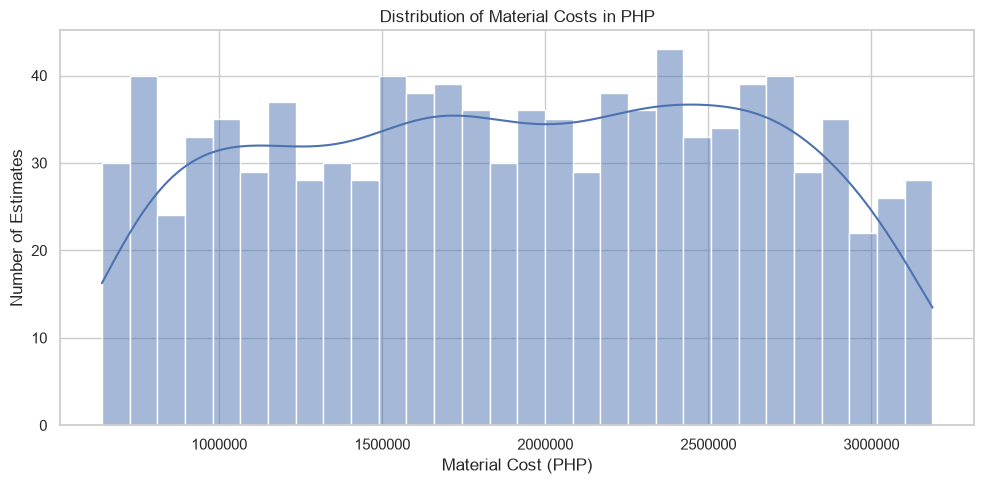

In [37]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=estimates_clean,
    x=material_cost_col,
    bins=30,
    kde=True
)

plt.title("Distribution of Material Costs in PHP")
plt.xlabel("Material Cost (PHP)")
plt.ylabel("Number of Estimates")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 6.4 Labor Cost Distribution

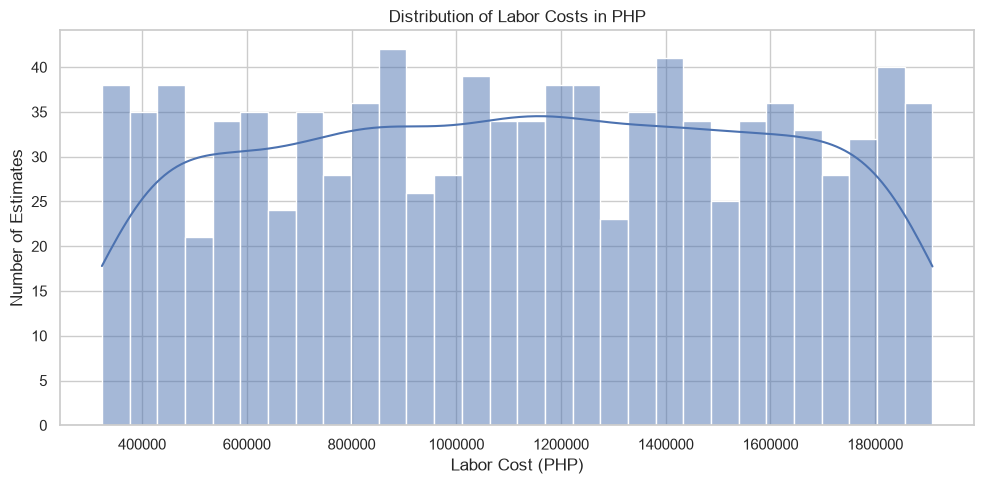

In [38]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=estimates_clean,
    x=labor_cost_col,
    bins=30,
    kde=True
)

plt.title("Distribution of Labor Costs in PHP")
plt.xlabel("Labor Cost (PHP)")
plt.ylabel("Number of Estimates")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 6.5 Total Estimate Distribution

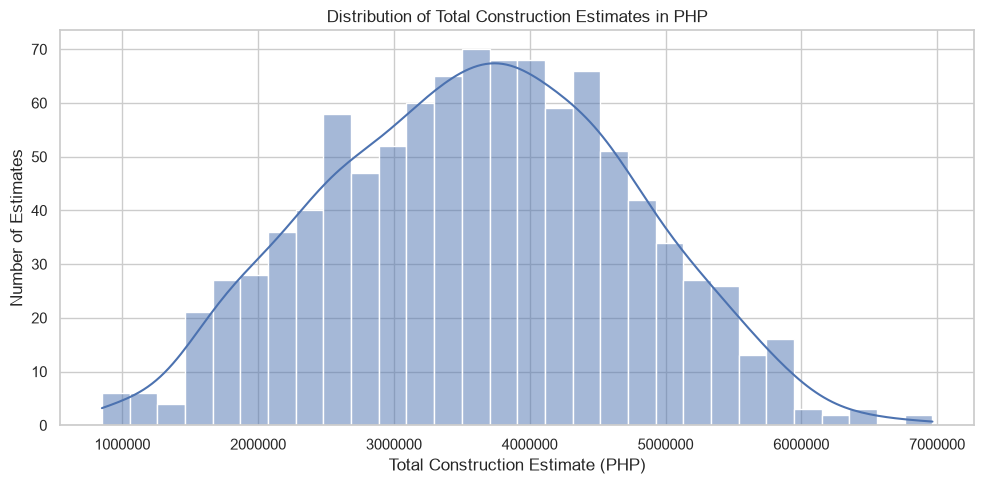

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=estimates_clean,
    x=total_estimate_col,
    bins=30,
    kde=True
)

plt.title("Distribution of Total Construction Estimates in PHP")
plt.xlabel("Total Construction Estimate (PHP)")
plt.ylabel("Number of Estimates")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 6.6 Profit Rate Distribution

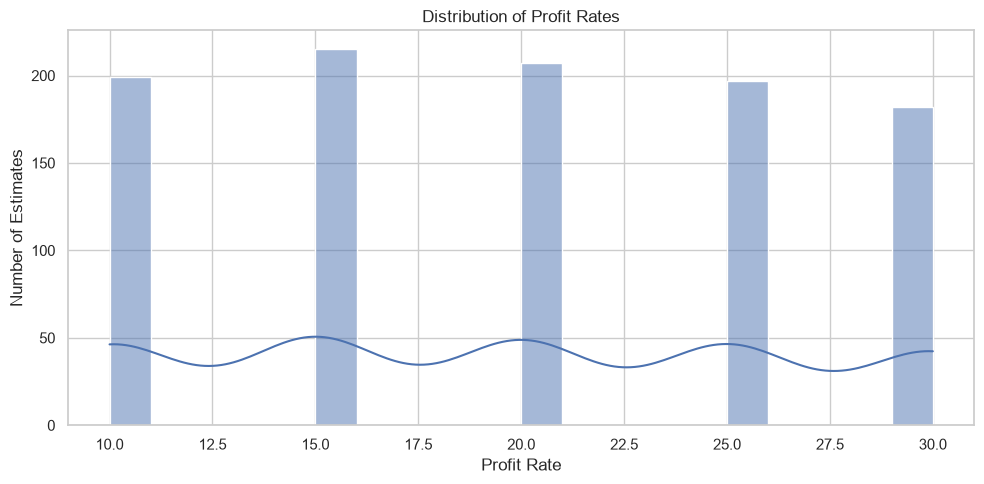

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=estimates_clean,
    x=profit_rate_col,
    bins=20,
    kde=True
)

plt.title("Distribution of Profit Rates")
plt.xlabel("Profit Rate")
plt.ylabel("Number of Estimates")

plt.tight_layout()
plt.show()

## 6.7 Discount / Markup Distribution

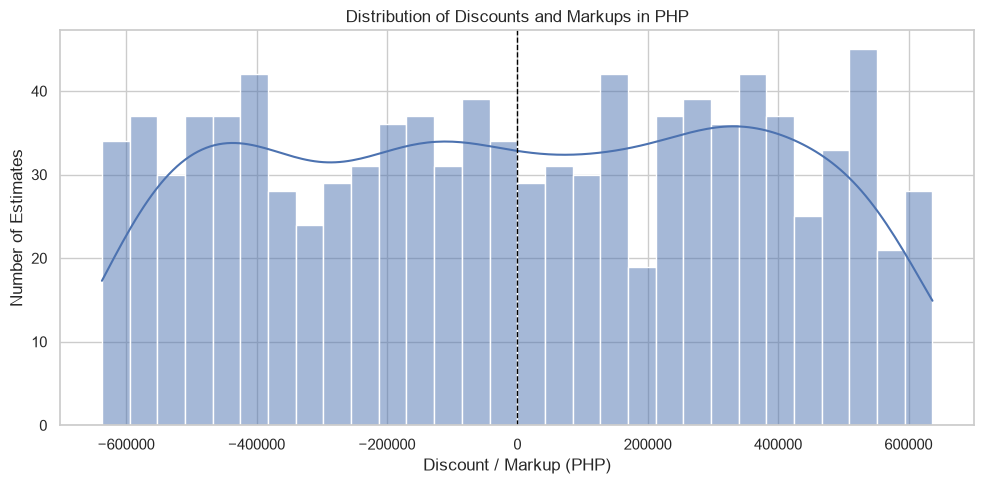

In [41]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=estimates_clean,
    x=markup_col,
    bins=30,
    kde=True
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Distribution of Discounts and Markups in PHP")
plt.xlabel("Discount / Markup (PHP)")
plt.ylabel("Number of Estimates")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 6.8 Descriptive Statistics

In [42]:
eda_columns = [
    material_cost_col,
    labor_cost_col,
    profit_rate_col,
    markup_col,
    total_estimate_col
]

summary_stats = estimates_clean[
    eda_columns
].describe().T

display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
material_costs_php,1000.0,1.908477e+06,7.146785e+05,640524.78,1.309892e+06,1915799.535,2.516587e+06,3187118.07
labor_cost_php,1000.0,1.120906e+06,4.610334e+05,323325.27,7.314221e+05,1122513.615,1.514770e+06,1909386.63
profit_rate,1000.0,1.974000e+01,6.955629e+00,10.00,1.500000e+01,20.000,2.500000e+01,30.00
discount_or_markup_php,1000.0,-4.688440e+03,3.669152e+05,-637270.47,-3.255746e+05,-8359.110,3.177738e+05,636759.99
total_estimate_php,1000.0,3.622474e+06,1.114472e+06,849894.96,2.812062e+06,3644913.345,4.421720e+06,6965844.17


## 6.9 Skewness

In [43]:
skewness = (
    estimates_clean[eda_columns]
    .skew()
    .sort_values(ascending=False)
    .to_frame("Skewness")
)

display(skewness)

,Skewness
profit_rate,0.055041
total_estimate_php,-0.001761
discount_or_markup_php,-0.017652
labor_cost_php,-0.020822
material_costs_php,-0.040688


## 6.10 Cost Boxplots

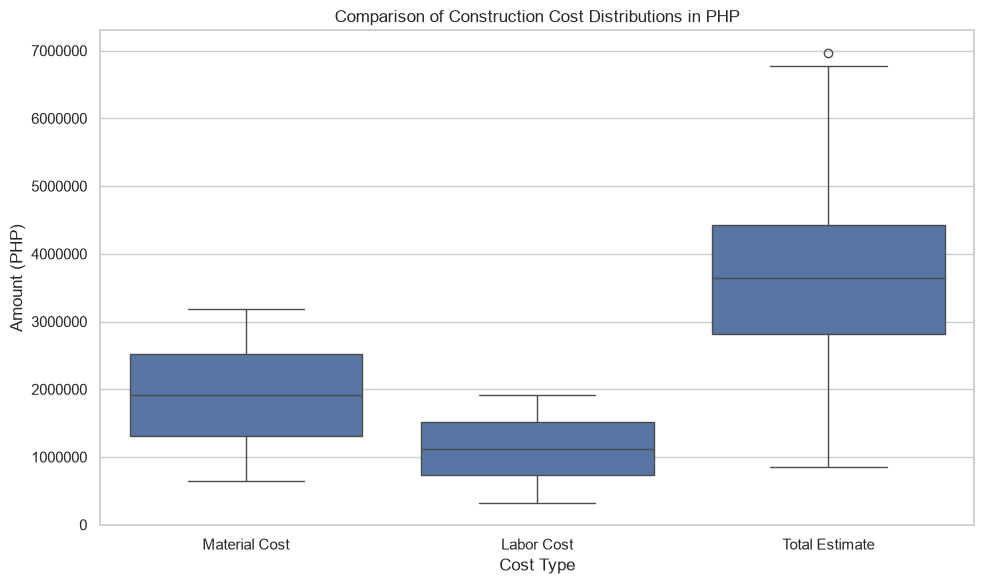

In [44]:
cost_columns = [
    material_cost_col,
    labor_cost_col,
    total_estimate_col
]

cost_plot_data = estimates_clean[
    cost_columns
].melt(
    var_name="Cost Type",
    value_name="Amount"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=cost_plot_data,
    x="Cost Type",
    y="Amount"
)

plt.title("Comparison of Construction Cost Distributions in PHP")
plt.xlabel("Cost Type")
plt.ylabel("Amount (PHP)")

plt.xticks(
    ticks=[0, 1, 2],
    labels=[
        "Material Cost",
        "Labor Cost",
        "Total Estimate"
    ]
)

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

# 7. Bivariate Analysis

## 7.1 Material Cost vs Total Estimate

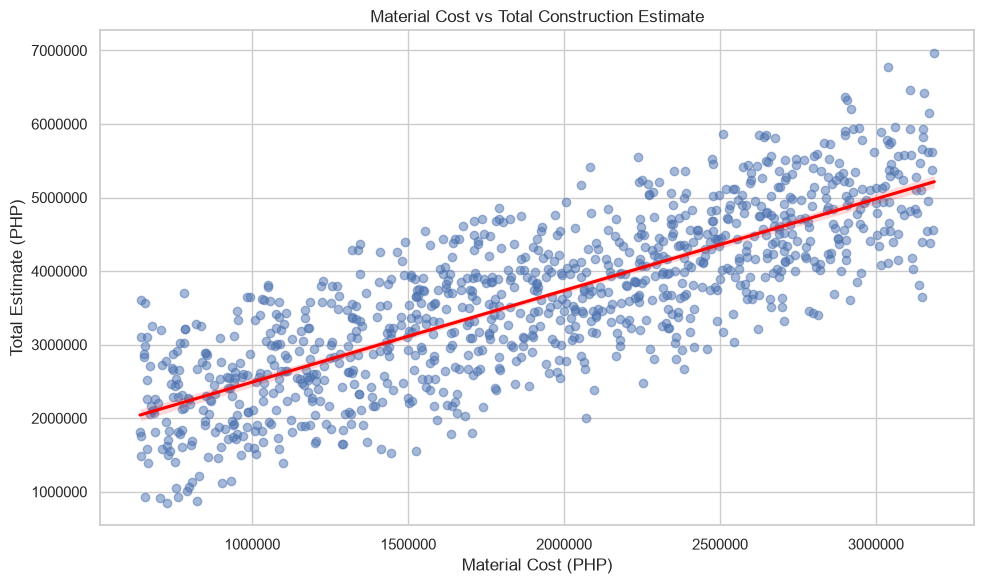

In [45]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=estimates_clean,
    x=material_cost_col,
    y=total_estimate_col,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Material Cost vs Total Construction Estimate")
plt.xlabel("Material Cost (PHP)")
plt.ylabel("Total Estimate (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="both"
)

plt.tight_layout()
plt.show()

## 7.2 Labor Cost vs Total Estimate

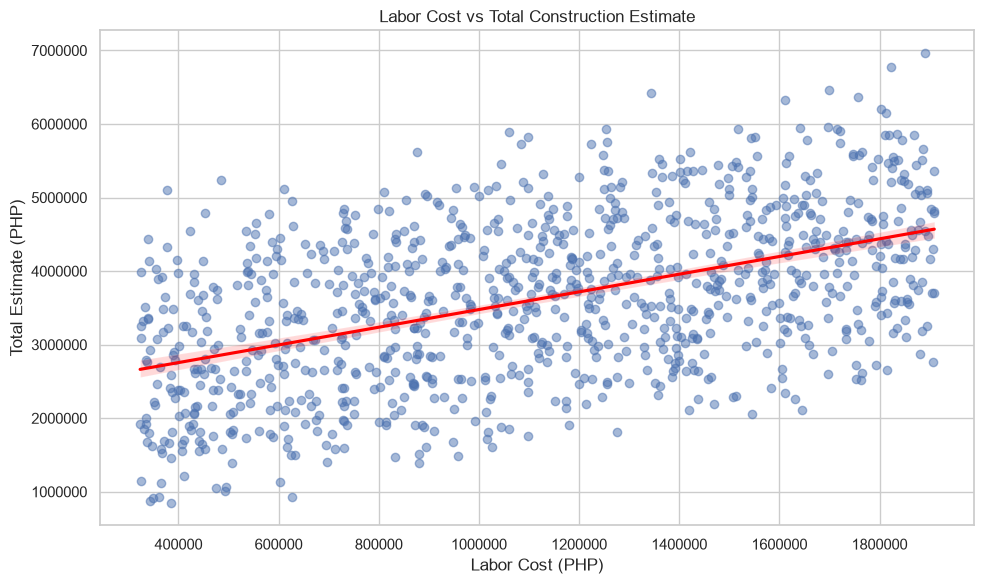

In [46]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=estimates_clean,
    x=labor_cost_col,
    y=total_estimate_col,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Labor Cost vs Total Construction Estimate")
plt.xlabel("Labor Cost (PHP)")
plt.ylabel("Total Estimate (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="both"
)

plt.tight_layout()
plt.show()

## 7.3 Profit Rate vs Total Estimate

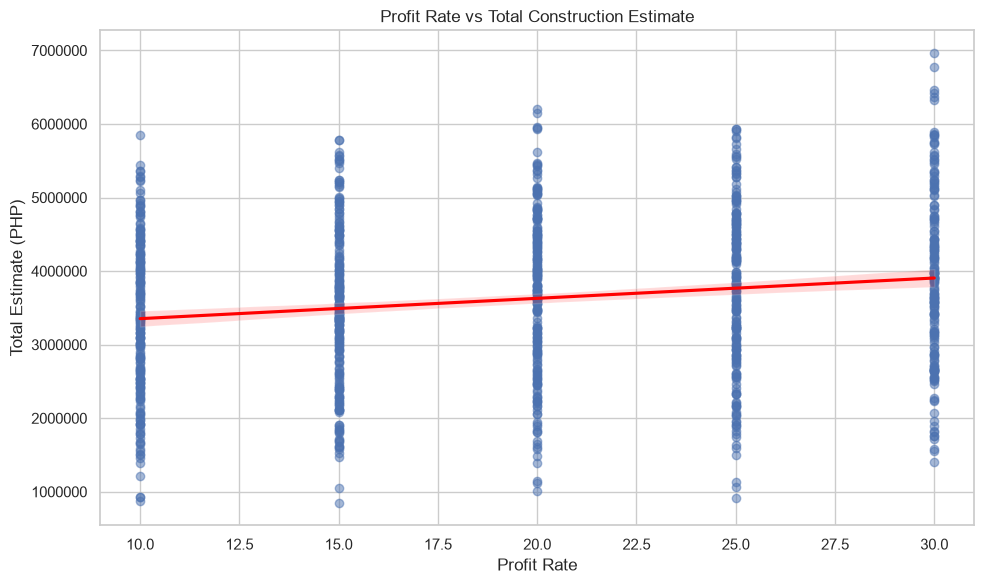

In [47]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=estimates_clean,
    x=profit_rate_col,
    y=total_estimate_col,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Profit Rate vs Total Construction Estimate")
plt.xlabel("Profit Rate")
plt.ylabel("Total Estimate (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

## 7.4 Discount / Markup vs Total Estimate

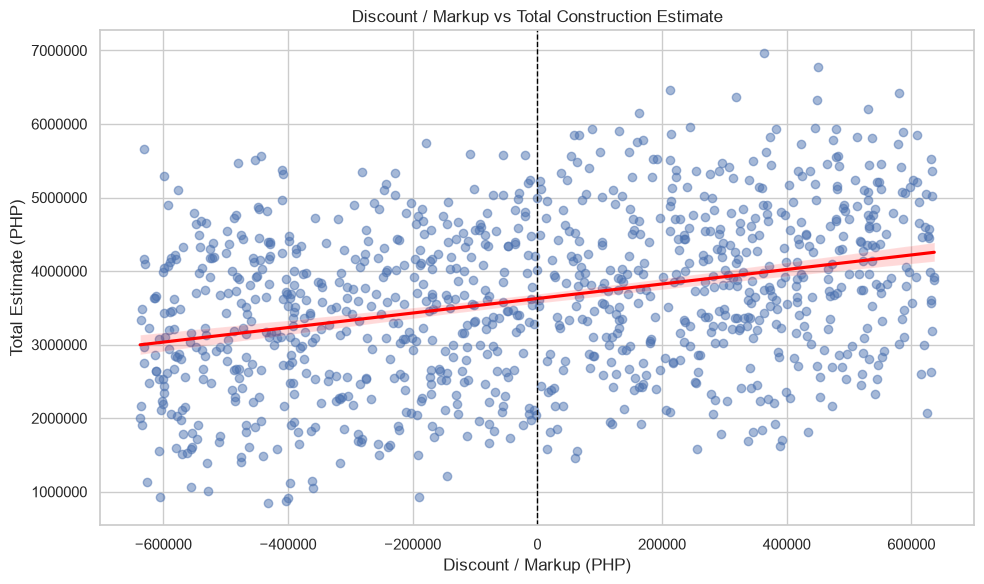

In [48]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=estimates_clean,
    x=markup_col,
    y=total_estimate_col,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Discount / Markup vs Total Construction Estimate")
plt.xlabel("Discount / Markup (PHP)")
plt.ylabel("Total Estimate (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="both"
)

plt.tight_layout()
plt.show()

## 7.5 Calculate the relationships numerically

In [49]:
bivariate_columns = [
    material_cost_col,
    labor_cost_col,
    profit_rate_col,
    markup_col,
    total_estimate_col
]

total_estimate_correlations = (
    estimates_clean[bivariate_columns]
    .corr()[total_estimate_col]
    .sort_values(ascending=False)
    .to_frame("Correlation with Total Estimate")
)

display(total_estimate_correlations)

,Correlation with Total Estimate
total_estimate_php,1.000000
material_costs_php,0.798886
labor_cost_php,0.497173
discount_or_markup_php,0.325117
profit_rate,0.172433


## 7.6 Material vs Labor Cost

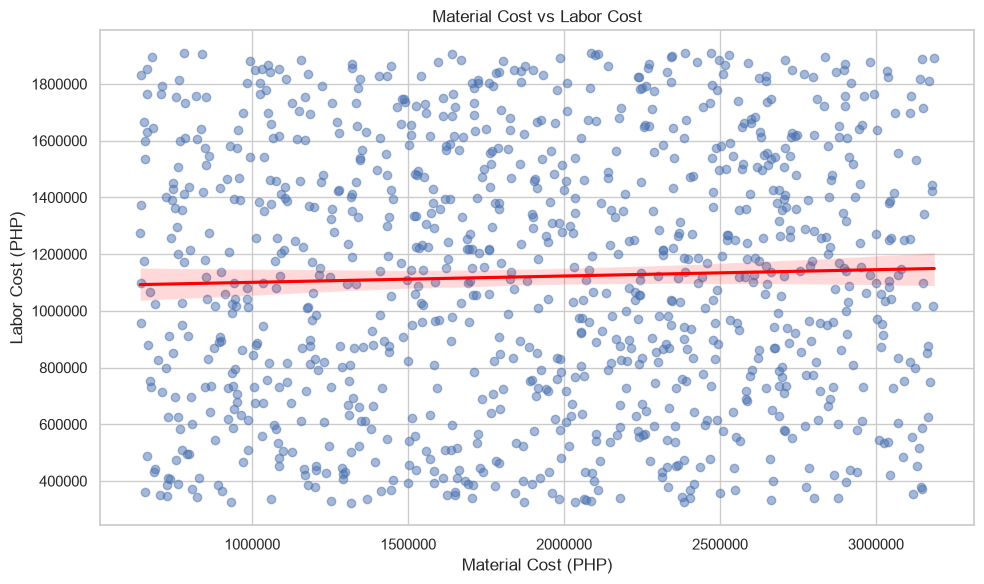

In [50]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=estimates_clean,
    x=material_cost_col,
    y=labor_cost_col,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Material Cost vs Labor Cost")
plt.xlabel("Material Cost (PHP)")
plt.ylabel("Labor Cost (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="both"
)

plt.tight_layout()
plt.show()

# 8. Categorical Analysis

## 8.1 Pricing Policy Reason Distribution

In [52]:
policy_counts = (
    estimates_clean["policy_reason"]
    .value_counts()
    .reset_index()
)

policy_counts.columns = [
    "Policy Reason",
    "Number of Estimates"
]

display(policy_counts)

,Policy Reason,Number of Estimates
0,Strategic importance of this client justifies ...,224
1,"This project includes additional risks, necess...",212
2,Market conditions require competitive pricing ...,199
3,"The client is a repeat customer, deserving a l...",190
4,This client is new but has potential for growth.,175


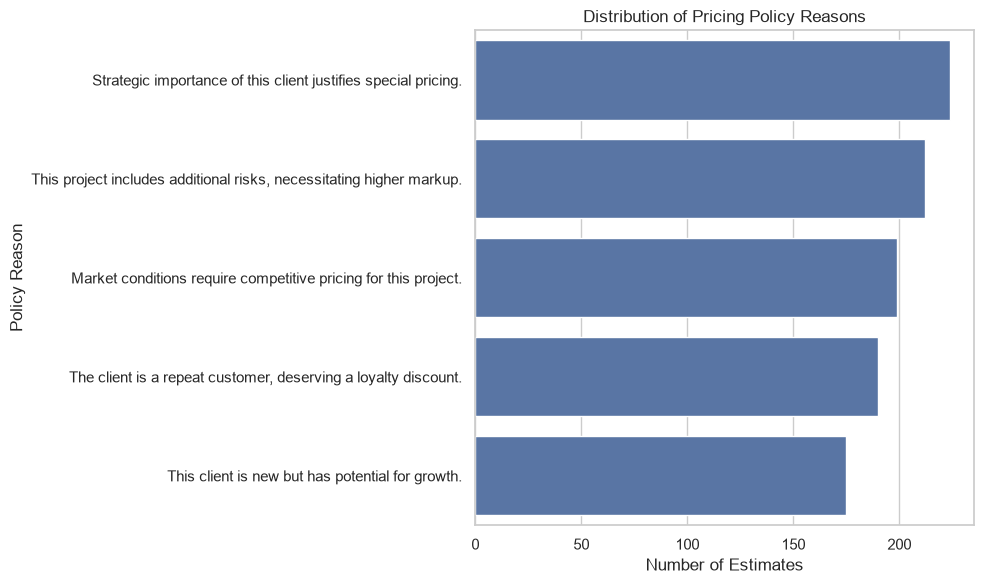

In [53]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=estimates_clean,
    y="policy_reason",
    order=estimates_clean["policy_reason"].value_counts().index
)

plt.title("Distribution of Pricing Policy Reasons")
plt.xlabel("Number of Estimates")
plt.ylabel("Policy Reason")

plt.tight_layout()
plt.show()

## 8.2 Policy Reason vs Total Estimate

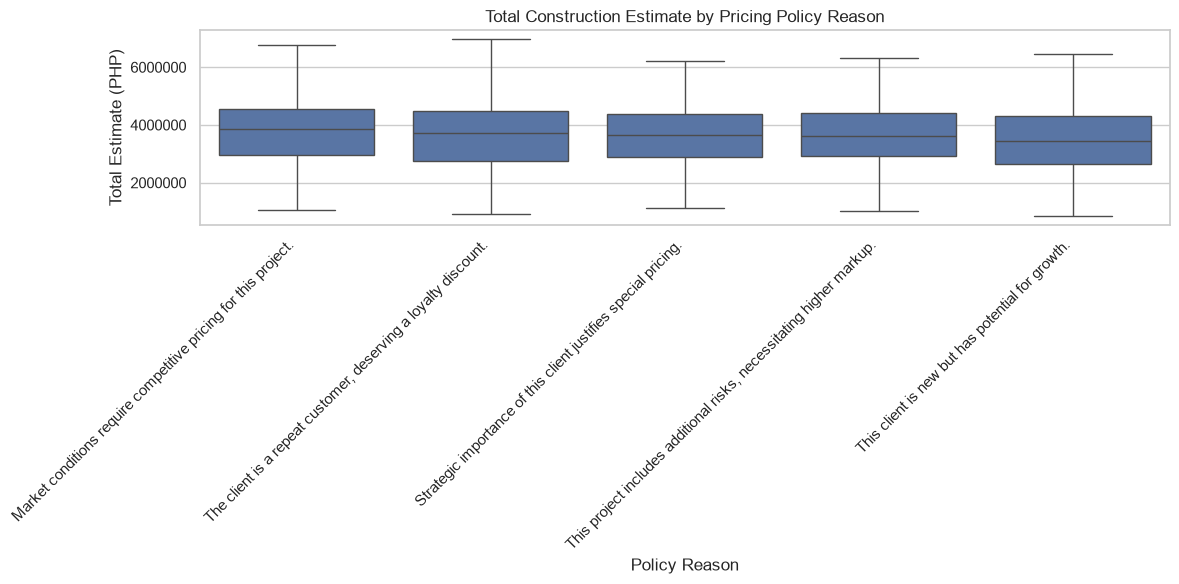

In [54]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=estimates_clean,
    x="policy_reason",
    y=total_estimate_col
)

plt.title("Total Construction Estimate by Pricing Policy Reason")
plt.xlabel("Policy Reason")
plt.ylabel("Total Estimate (PHP)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

## 8.3 Policy Reason Summary Statistics

In [55]:
policy_summary = (
    estimates_clean
    .groupby("policy_reason")[total_estimate_col]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .round(2)
    .sort_values(
        "median",
        ascending=False
    )
)

display(policy_summary)

,count,mean,median,min,max
policy_reason,,,,,
Market conditions require competitive pricing for this project.,199,3785348.16,3843454.97,1055222.78,6769417.85
"The client is a repeat customer, deserving a loyalty discount.",190,3623123.10,3729105.86,916183.98,6965844.17
Strategic importance of this client justifies special pricing.,224,3645520.64,3641949.37,1124919.25,6198439.59
"This project includes additional risks, necessitating higher markup.",212,3607253.71,3617082.62,1012281.84,6323309.38
This client is new but has potential for growth.,175,3425497.21,3460556.68,849894.96,6462574.70


## 8.4 Material Category Distribution

In [56]:
material_category_counts = (
    materials_clean["material_category"]
    .value_counts()
    .reset_index()
)

material_category_counts.columns = [
    "Material Category",
    "Number of Materials"
]

display(material_category_counts)

,Material Category,Number of Materials
0,Rebar,45
1,Metal Track,15
2,Metal Stud,15
3,I-Beam,13
4,Tubular,12
5,C-Purlins,12
6,Flat Bar,11
7,Angle Bar,11
8,Round Bar,6
9,MS Plate,6


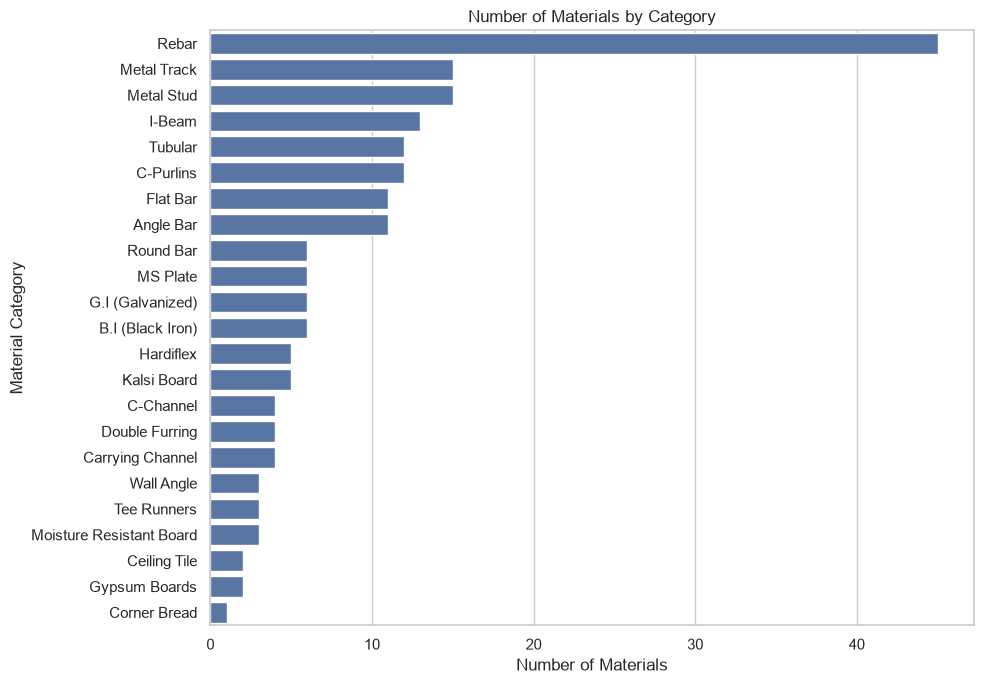

In [57]:
plt.figure(figsize=(10, 7))

sns.countplot(
    data=materials_clean,
    y="material_category",
    order=materials_clean["material_category"].value_counts().index
)

plt.title("Number of Materials by Category")
plt.xlabel("Number of Materials")
plt.ylabel("Material Category")

plt.tight_layout()
plt.show()

## 8.5 Material Category vs Unit Price

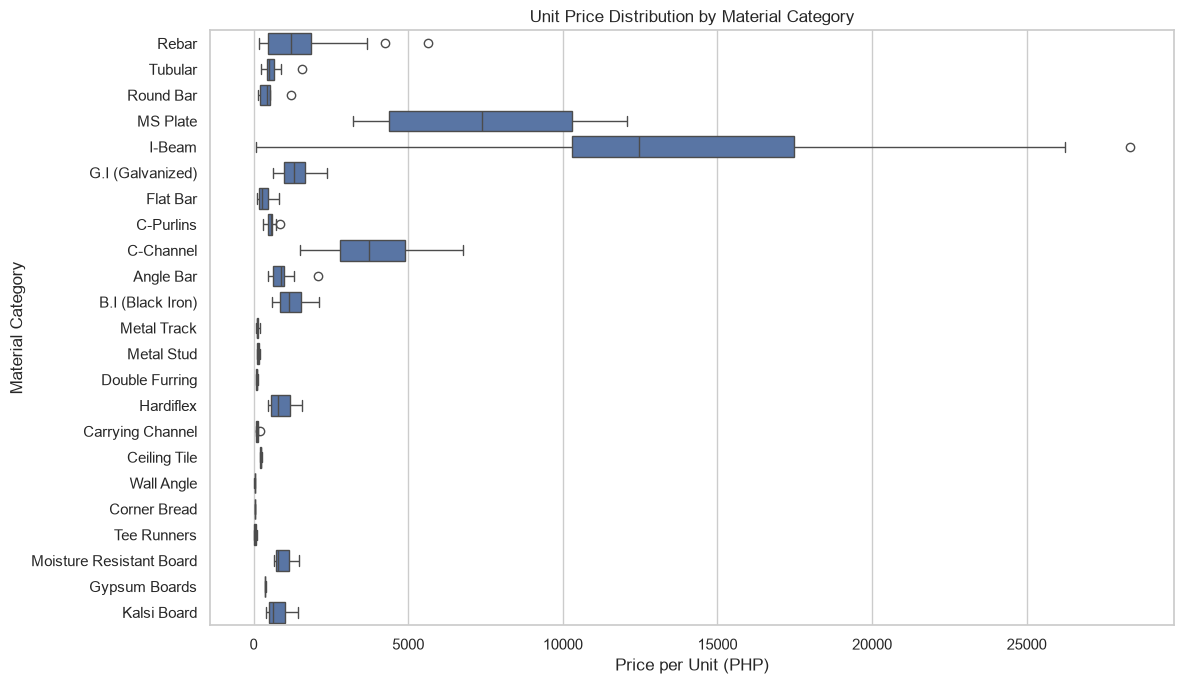

In [58]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=materials_clean,
    x="price_per_unit",
    y="material_category"
)

plt.title("Unit Price Distribution by Material Category")
plt.xlabel("Price per Unit (PHP)")
plt.ylabel("Material Category")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 8.6 Median Material Price by Category

In [59]:
category_price_summary = (
    materials_clean
    .groupby("material_category")["price_per_unit"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .round(2)
    .sort_values(
        "median",
        ascending=False
    )
)

display(category_price_summary)

,count,mean,median,min,max
material_category,,,,,
I-Beam,13,13829.78,12473.00,64.14,28348.00
MS Plate,6,7446.50,7375.50,3204.00,12085.00
C-Channel,4,3935.21,3729.78,1501.00,6780.28
G.I (Galvanized),6,1377.00,1305.00,622.00,2386.00
Rebar,45,1441.18,1208.00,175.00,5655.00
B.I (Black Iron),6,1235.17,1134.00,600.00,2128.00
Angle Bar,11,919.27,885.00,460.00,2084.00
Hardiflex,5,920.17,794.44,479.13,1574.72
Moisture Resistant Board,3,972.63,780.55,657.63,1479.71


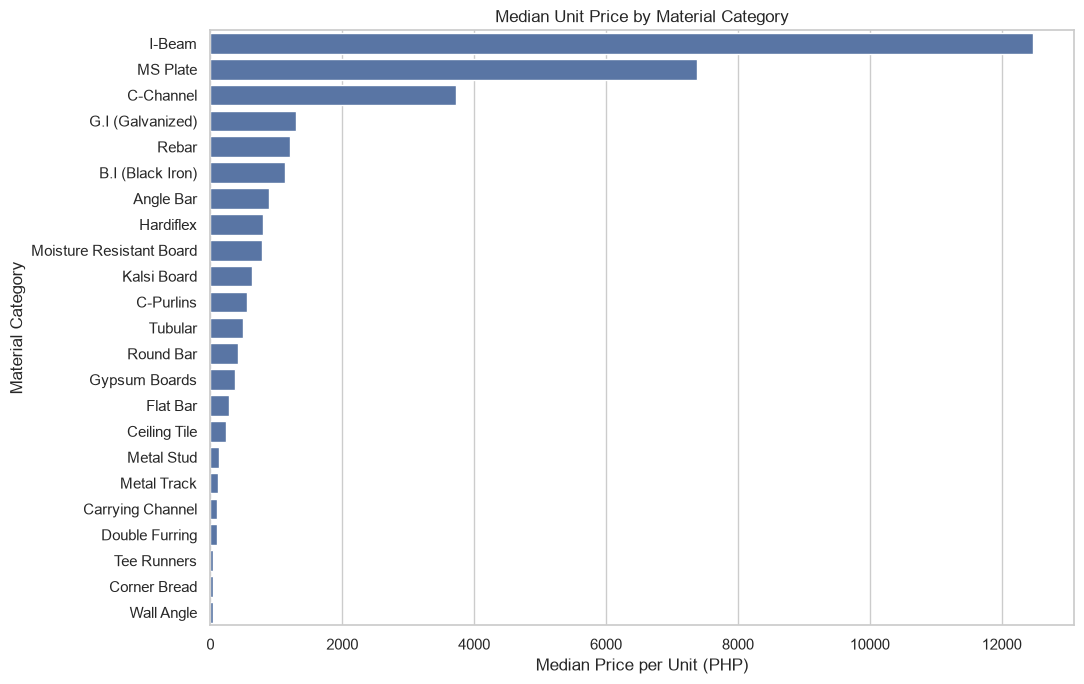

In [60]:
median_category_prices = (
    materials_clean
    .groupby("material_category")["price_per_unit"]
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=median_category_prices,
    x="price_per_unit",
    y="material_category"
)

plt.title("Median Unit Price by Material Category")
plt.xlabel("Median Price per Unit (PHP)")
plt.ylabel("Material Category")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 8.7 Material Type Distribution

In [61]:
material_type_counts = (
    materials_clean["material_type"]
    .value_counts()
    .reset_index()
)

material_type_counts.columns = [
    "Material Type",
    "Number of Materials"
]

display(material_type_counts)

,Material Type,Number of Materials
0,Structural Type,132
1,"Walls, Floors and Ceiling Materials",62


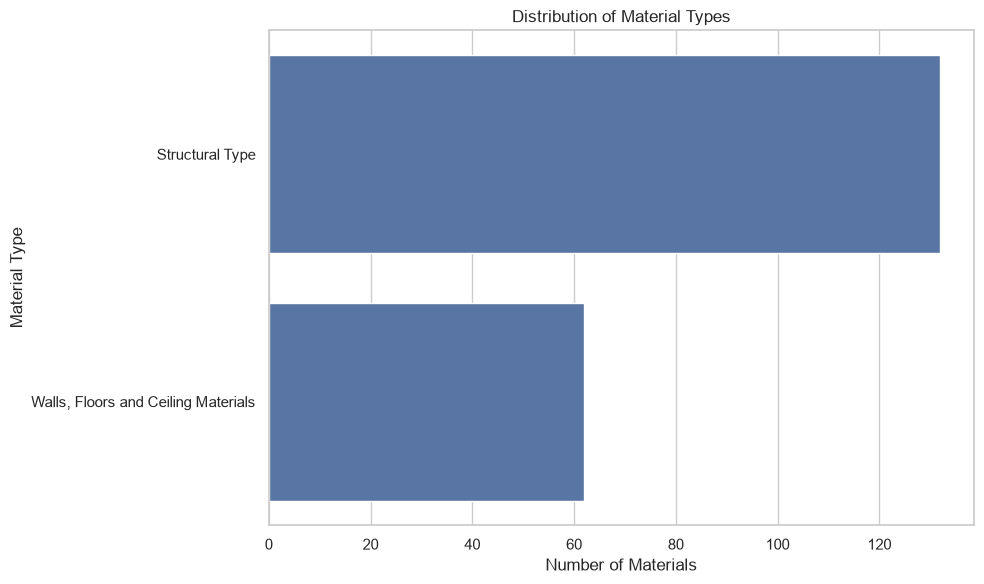

In [62]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=materials_clean,
    y="material_type",
    order=materials_clean["material_type"].value_counts().index
)

plt.title("Distribution of Material Types")
plt.xlabel("Number of Materials")
plt.ylabel("Material Type")

plt.tight_layout()
plt.show()

# 9. Correlation Analysis

## 9.1 Create PHP Correlation Data

In [64]:
php_correlation_columns = [
    material_cost_col,
    labor_cost_col,
    profit_rate_col,
    markup_col,
    total_estimate_col
]

php_corr_data = estimates_clean[
    php_correlation_columns
].copy()

display(php_corr_data.head())

,material_costs_php,labor_cost_php,profit_rate,discount_or_markup_php,total_estimate_php
0,2806682.85,819065.16,10,69871.95,4058194.76
1,2903610.24,1140476.13,15,-410043.06,4240656.27
2,2147589.36,536067.81,25,629294.22,3983865.68
3,2329639.29,543852.63,20,516605.76,3964796.06
4,2384707.32,901188.63,30,-612448.38,3659216.36


## 9.2 Correlation Matrix

In [66]:
correlation_matrix = php_corr_data.corr()

display(
    correlation_matrix.round(3)
)

,material_costs_php,labor_cost_php,profit_rate,discount_or_markup_php,total_estimate_php
material_costs_php,1.000,0.035,-0.007,0.053,0.799
labor_cost_php,0.035,1.000,0.004,-0.074,0.497
profit_rate,-0.007,0.004,1.000,-0.040,0.172
discount_or_markup_php,0.053,-0.074,-0.040,1.000,0.325
total_estimate_php,0.799,0.497,0.172,0.325,1.000


## 9.3 Correlation Heatmap

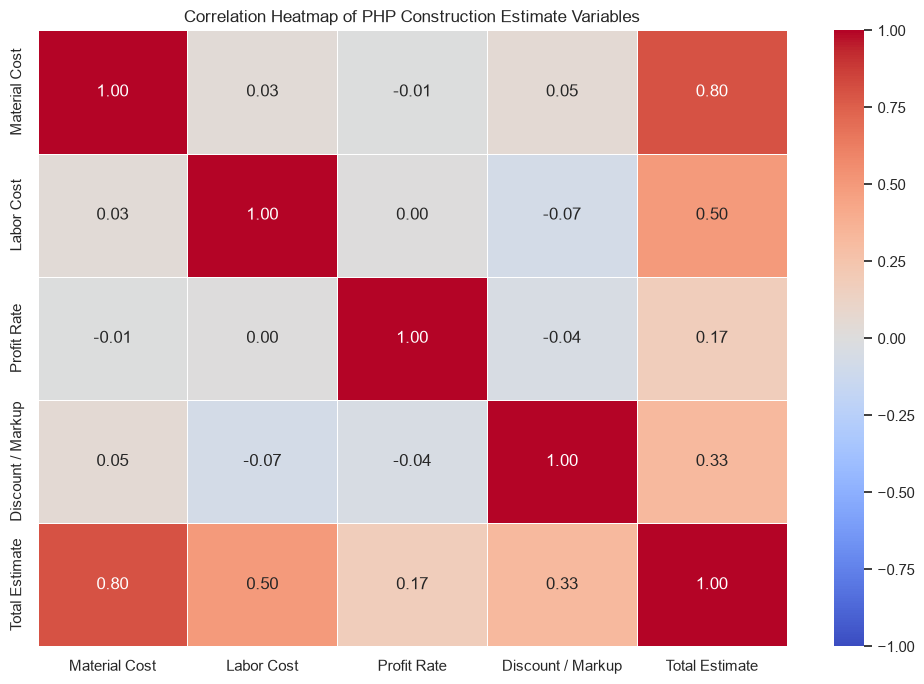

In [67]:
correlation_labels = {
    material_cost_col: "Material Cost",
    labor_cost_col: "Labor Cost",
    profit_rate_col: "Profit Rate",
    markup_col: "Discount / Markup",
    total_estimate_col: "Total Estimate"
}

correlation_display = correlation_matrix.rename(
    index=correlation_labels,
    columns=correlation_labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_display,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of PHP Construction Estimate Variables")

plt.tight_layout()
plt.show()

## 9.4 Correlation with Total Estimate

In [68]:
target_correlations = (
    correlation_matrix[total_estimate_col]
    .drop(total_estimate_col)
    .sort_values(
        key=abs,
        ascending=False
    )
    .to_frame("Correlation with Total Estimate")
)

target_correlations.index = [
    correlation_labels.get(index, index)
    for index in target_correlations.index
]

display(
    target_correlations.round(3)
)

,Correlation with Total Estimate
Material Cost,0.799
Labor Cost,0.497
Discount / Markup,0.325
Profit Rate,0.172


## 9.5 Visualize Target Correlations

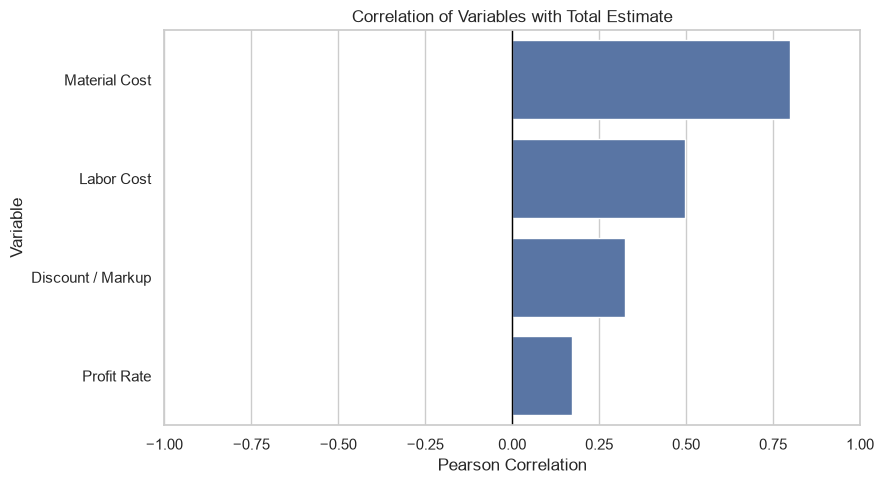

In [69]:
target_corr_plot = (
    target_correlations
    .reset_index()
)

target_corr_plot.columns = [
    "Variable",
    "Correlation"
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=target_corr_plot,
    x="Correlation",
    y="Variable"
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.xlim(-1, 1)

plt.title("Correlation of Variables with Total Estimate")
plt.xlabel("Pearson Correlation")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

## 9.6 Multicollinearity Check

In [70]:
predictor_columns = [
    material_cost_col,
    labor_cost_col,
    profit_rate_col,
    markup_col
]

predictor_corr = (
    estimates_clean[predictor_columns]
    .corr()
)

predictor_corr_display = predictor_corr.rename(
    index=correlation_labels,
    columns=correlation_labels
)

display(
    predictor_corr_display.round(3)
)

,Material Cost,Labor Cost,Profit Rate,Discount / Markup
Material Cost,1.000,0.035,-0.007,0.053
Labor Cost,0.035,1.000,0.004,-0.074
Profit Rate,-0.007,0.004,1.000,-0.040
Discount / Markup,0.053,-0.074,-0.040,1.000


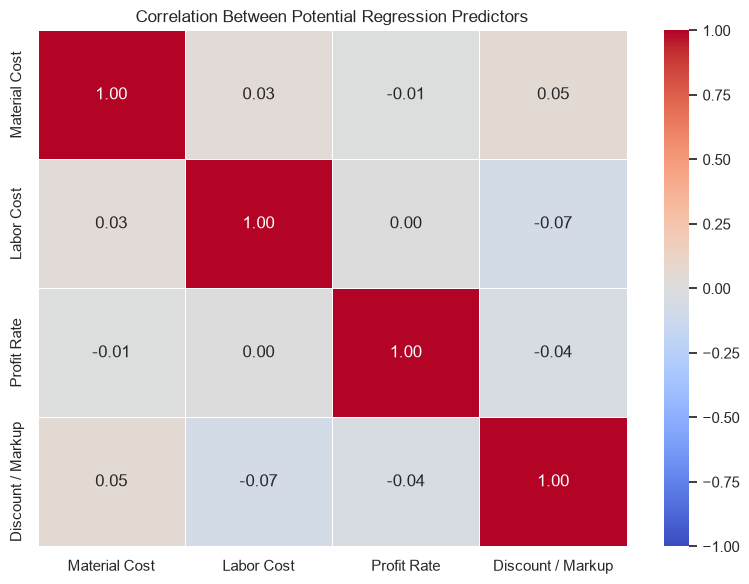

In [71]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    predictor_corr_display,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Potential Regression Predictors")

plt.tight_layout()
plt.show()

# 10. Outlier Analysis

## 10.1 IQR Outlier Detection Function

In [72]:
def find_outliers_iqr(df, column):
    
    data = df[column].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound

## 10.2 Material Cost Outliers

In [73]:
material_outliers, material_lower, material_upper = find_outliers_iqr(
    estimates_clean,
    material_cost_col
)

print("Material Cost Outlier Analysis")
print("=" * 50)

print(f"Lower Bound: PHP {material_lower:,.2f}")
print(f"Upper Bound: PHP {material_upper:,.2f}")
print(f"Number of Outliers: {len(material_outliers)}")
print(
    f"Percentage of Dataset: "
    f"{len(material_outliers) / len(estimates_clean) * 100:.2f}%"
)

Material Cost Outlier Analysis
Lower Bound: PHP -500,150.76
Upper Bound: PHP 4,326,629.07
Number of Outliers: 0
Percentage of Dataset: 0.00%


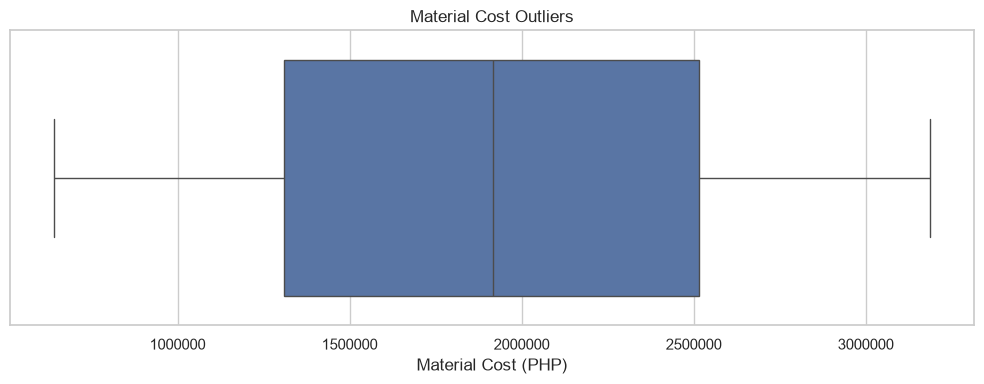

In [74]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=estimates_clean[material_cost_col]
)

plt.title("Material Cost Outliers")
plt.xlabel("Material Cost (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 10.3 Labor Cost Outliers

In [75]:
labor_outliers, labor_lower, labor_upper = find_outliers_iqr(
    estimates_clean,
    labor_cost_col
)

print("Labor Cost Outlier Analysis")
print("=" * 50)

print(f"Lower Bound: PHP {labor_lower:,.2f}")
print(f"Upper Bound: PHP {labor_upper:,.2f}")
print(f"Number of Outliers: {len(labor_outliers)}")
print(
    f"Percentage of Dataset: "
    f"{len(labor_outliers) / len(estimates_clean) * 100:.2f}%"
)

Labor Cost Outlier Analysis
Lower Bound: PHP -443,599.14
Upper Bound: PHP 2,689,790.91
Number of Outliers: 0
Percentage of Dataset: 0.00%


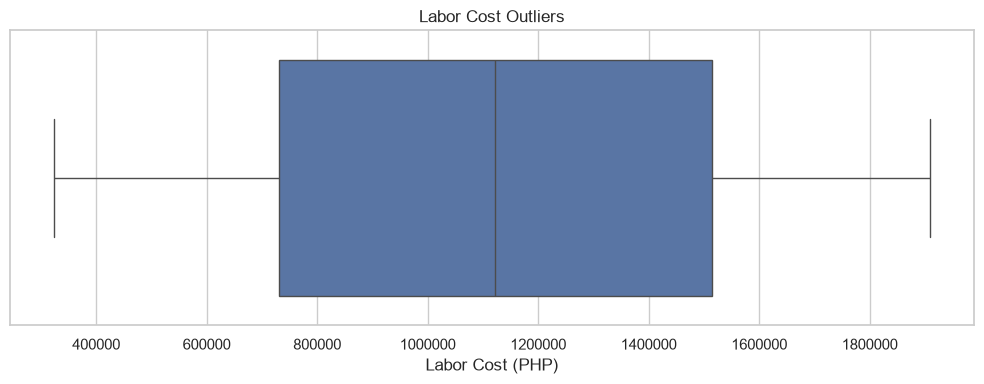

In [76]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=estimates_clean[labor_cost_col]
)

plt.title("Labor Cost Outliers")
plt.xlabel("Labor Cost (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 10.4 Total Estimate Outliers

In [77]:
estimate_outliers, estimate_lower, estimate_upper = find_outliers_iqr(
    estimates_clean,
    total_estimate_col
)

print("Total Estimate Outlier Analysis")
print("=" * 50)

print(f"Lower Bound: PHP {estimate_lower:,.2f}")
print(f"Upper Bound: PHP {estimate_upper:,.2f}")
print(f"Number of Outliers: {len(estimate_outliers)}")
print(
    f"Percentage of Dataset: "
    f"{len(estimate_outliers) / len(estimates_clean) * 100:.2f}%"
)

Total Estimate Outlier Analysis
Lower Bound: PHP 397,574.59
Upper Bound: PHP 6,836,207.79
Number of Outliers: 1
Percentage of Dataset: 0.10%


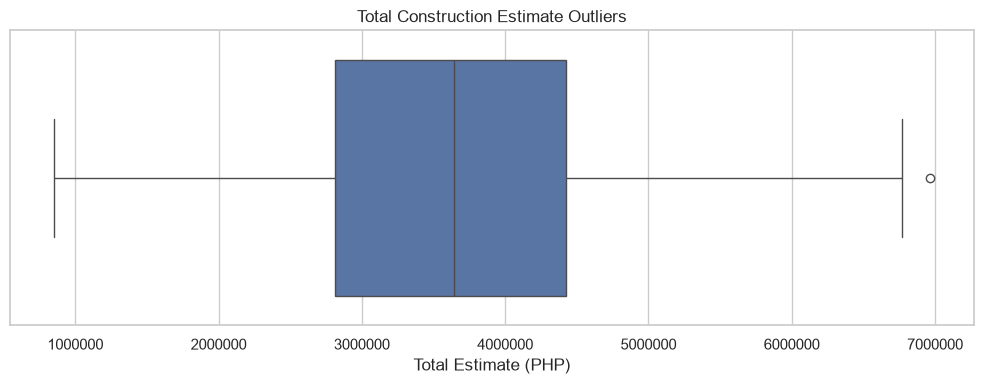

In [78]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=estimates_clean[total_estimate_col]
)

plt.title("Total Construction Estimate Outliers")
plt.xlabel("Total Estimate (PHP)")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 10.5 Inspect the Total Estimate Outliers

In [79]:
outlier_columns = [
    material_cost_col,
    labor_cost_col,
    profit_rate_col,
    markup_col,
    "policy_reason",
    total_estimate_col
]

display(
    estimate_outliers[
        outlier_columns
    ]
    .sort_values(
        total_estimate_col,
        ascending=False
    )
    .head(20)
)

,material_costs_php,labor_cost_php,profit_rate,discount_or_markup_php,policy_reason,total_estimate_php
737,3187118.07,1891392.21,30,363780.81,"The client is a repeat customer, deserving a l...",6965844.17


## 10.6 Compare Outlier Counts

In [80]:
outlier_summary = pd.DataFrame({
    "Variable": [
        "Material Cost",
        "Labor Cost",
        "Total Estimate"
    ],
    "Outlier Count": [
        len(material_outliers),
        len(labor_outliers),
        len(estimate_outliers)
    ],
    "Outlier Percentage": [
        len(material_outliers) / len(estimates_clean) * 100,
        len(labor_outliers) / len(estimates_clean) * 100,
        len(estimate_outliers) / len(estimates_clean) * 100
    ]
})

outlier_summary["Outlier Percentage"] = (
    outlier_summary["Outlier Percentage"]
    .round(2)
)

display(outlier_summary)

,Variable,Outlier Count,Outlier Percentage
0,Material Cost,0,0.0
1,Labor Cost,0,0.0
2,Total Estimate,1,0.1


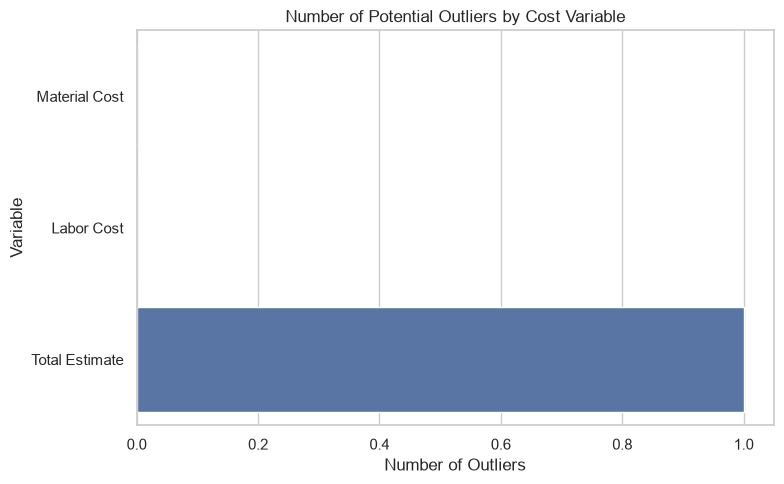

In [81]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=outlier_summary,
    x="Outlier Count",
    y="Variable"
)

plt.title("Number of Potential Outliers by Cost Variable")
plt.xlabel("Number of Outliers")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

# 11. Material Price Analysis

## This section examines the Philippine building material reference dataset to understand material price distributions, category-level differences, high-cost materials, and price variability.

### The material reference data provides additional local pricing context for the BuildWise construction cost estimation application.

## 11.1 Material Price Distribution

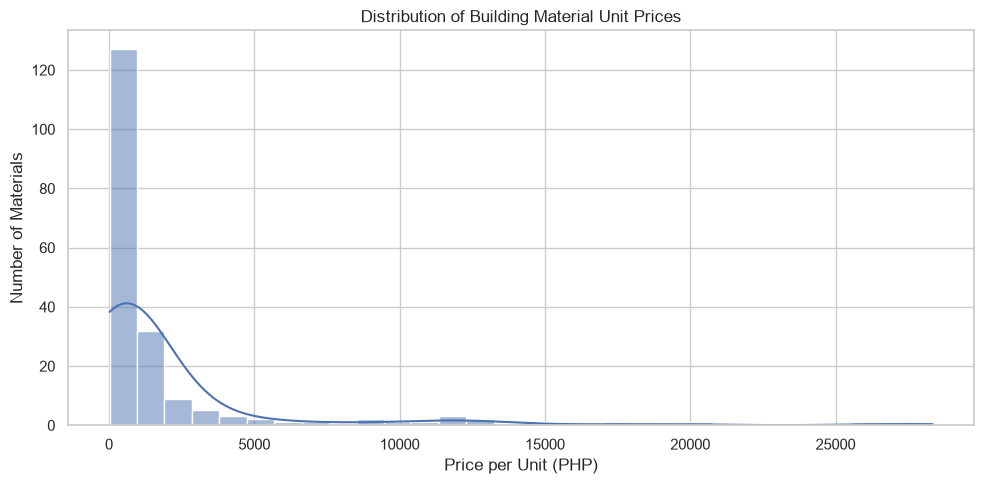

In [82]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=materials_clean,
    x="price_per_unit",
    bins=30,
    kde=True
)

plt.title("Distribution of Building Material Unit Prices")
plt.xlabel("Price per Unit (PHP)")
plt.ylabel("Number of Materials")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 11.2 Material Price Summary

In [83]:
material_price_summary = (
    materials_clean["price_per_unit"]
    .describe()
    .to_frame("Price per Unit (PHP)")
)

display(material_price_summary)

,Price per Unit (PHP)
count,194.000000
mean,1905.230309
std,4079.416887
min,19.170000
25%,193.837500
50%,562.295000
75%,1472.032500
max,28348.000000


In [84]:
material_median = materials_clean["price_per_unit"].median()

print(
    f"Median Material Price: PHP {material_median:,.2f}"
)

Median Material Price: PHP 562.30


## 11.3 Most Expensive Materials

In [85]:
top_expensive_materials = (
    materials_clean
    .sort_values(
        "price_per_unit",
        ascending=False
    )
    .head(15)
)

display(
    top_expensive_materials[
        [
            "material_type",
            "material_category",
            "description",
            "size_dimension",
            "price_per_unit"
        ]
    ]
)

,material_type,material_category,description,size_dimension,price_per_unit
69,Structural Type,I-Beam,"I-Beam, Wide Flange","8 x 8 x 48# (F=166mm, W=205mm, tf=17.4mm, tw=1...",28348.00
74,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6-1/2 X 28# (F=166mm, W=205mm, tf=11.6mm, ...",26231.00
70,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 8 X 40# (F=205mm, W=210mm, tf=14.2mm, tw=9...",19957.00
71,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 8 X 35# (F=204mm, W=206mm, tf=12.6mm, tw=7...",17461.00
72,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 8 X 31# (F=203mm, W=203mm, tf=11mm, tw=7.2mm)",14450.00
73,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6-1/2 X 28# (F=166mm, W=205mm, tf=11.6mm, ...",13116.00
75,Structural Type,I-Beam,"I-Beam, Wide Flange","6 X 6 X 25# (F=154mm, W=162mm, tf=11.6mm, tw=8...",12473.00
77,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6.5 X 21# (F=157mm, W=210mm, tf=10.1mm, tw...",12257.00
68,Structural Type,MS Plate,Mild Steel Plate,"Thickness: 12mm , Size: 4 ft x 8 ft",12085.00
76,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6.5 X 24# (F=165mm, W=201mm, tf=10.1mm, tw...",11440.00


## 11.4 Visualize Most Expensive Materials

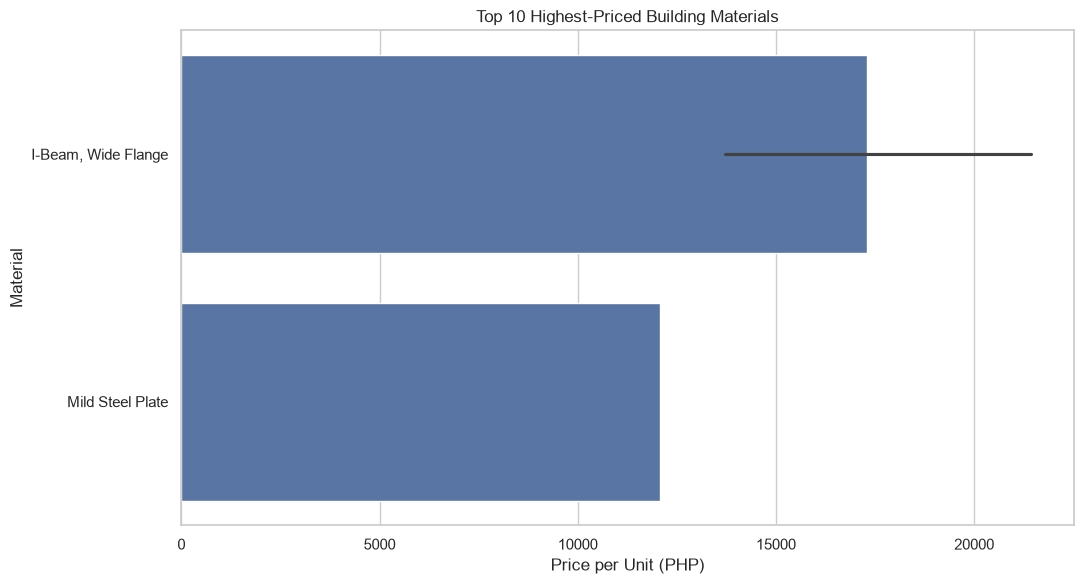

In [86]:
top_10_materials = (
    materials_clean
    .sort_values(
        "price_per_unit",
        ascending=False
    )
    .head(10)
    .copy()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_materials,
    x="price_per_unit",
    y="description"
)

plt.title("Top 10 Highest-Priced Building Materials")
plt.xlabel("Price per Unit (PHP)")
plt.ylabel("Material")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

## 11.5 Price Variability by Category

In [87]:
category_variability = (
    materials_clean
    .groupby("material_category")["price_per_unit"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

category_variability["price_range"] = (
    category_variability["max"]
    - category_variability["min"]
)

category_variability = (
    category_variability
    .sort_values(
        "price_range",
        ascending=False
    )
)

display(category_variability)

,count,mean,median,std,min,max,price_range
material_category,,,,,,,
I-Beam,13,13829.78,12473.00,7807.93,64.14,28348.00,28283.86
MS Plate,6,7446.50,7375.50,3676.90,3204.00,12085.00,8881.00
Rebar,45,1441.18,1208.00,1216.77,175.00,5655.00,5480.00
C-Channel,4,3935.21,3729.78,2210.36,1501.00,6780.28,5279.28
G.I (Galvanized),6,1377.00,1305.00,630.32,622.00,2386.00,1764.00
Angle Bar,11,919.27,885.00,454.60,460.00,2084.00,1624.00
B.I (Black Iron),6,1235.17,1134.00,567.28,600.00,2128.00,1528.00
Tubular,12,606.00,487.50,347.24,244.00,1551.00,1307.00
Hardiflex,5,920.17,794.44,458.44,479.13,1574.72,1095.59


## 11.6 Material Dataset Outliers

In [88]:
material_price_outliers, price_lower, price_upper = find_outliers_iqr(
    materials_clean,
    "price_per_unit"
)

print("Material Price Outlier Analysis")
print("=" * 50)

print(f"Lower Bound: PHP {price_lower:,.2f}")
print(f"Upper Bound: PHP {price_upper:,.2f}")

print(
    f"Number of Potential Outliers: "
    f"{len(material_price_outliers)}"
)

print(
    f"Percentage of Materials: "
    f"{len(material_price_outliers) / len(materials_clean) * 100:.2f}%"
)

Material Price Outlier Analysis
Lower Bound: PHP -1,723.45
Upper Bound: PHP 3,389.32
Number of Potential Outliers: 23
Percentage of Materials: 11.86%


In [89]:
display(
    material_price_outliers[
        [
            "material_type",
            "material_category",
            "description",
            "size_dimension",
            "price_per_unit"
        ]
    ]
    .sort_values(
        "price_per_unit",
        ascending=False
    )
)

,material_type,material_category,description,size_dimension,price_per_unit
69,Structural Type,I-Beam,"I-Beam, Wide Flange","8 x 8 x 48# (F=166mm, W=205mm, tf=17.4mm, tw=1...",28348.00
74,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6-1/2 X 28# (F=166mm, W=205mm, tf=11.6mm, ...",26231.00
70,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 8 X 40# (F=205mm, W=210mm, tf=14.2mm, tw=9...",19957.00
71,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 8 X 35# (F=204mm, W=206mm, tf=12.6mm, tw=7...",17461.00
72,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 8 X 31# (F=203mm, W=203mm, tf=11mm, tw=7.2mm)",14450.00
73,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6-1/2 X 28# (F=166mm, W=205mm, tf=11.6mm, ...",13116.00
75,Structural Type,I-Beam,"I-Beam, Wide Flange","6 X 6 X 25# (F=154mm, W=162mm, tf=11.6mm, tw=8...",12473.00
77,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6.5 X 21# (F=157mm, W=210mm, tf=10.1mm, tw...",12257.00
68,Structural Type,MS Plate,Mild Steel Plate,"Thickness: 12mm , Size: 4 ft x 8 ft",12085.00
76,Structural Type,I-Beam,"I-Beam, Wide Flange","8 X 6.5 X 24# (F=165mm, W=201mm, tf=10.1mm, tw...",11440.00


## 11.7 Duplicate Material Specifications

In [90]:
duplicate_check_columns = [
    "material_type",
    "material_category",
    "description",
    "size_dimension",
    "length"
]

duplicate_materials = materials_clean[
    materials_clean.duplicated(
        subset=duplicate_check_columns,
        keep=False
    )
]

print(
    "Potential Duplicate Material Specifications:",
    len(duplicate_materials)
)

display(
    duplicate_materials[
        duplicate_check_columns
        + ["price_per_unit"]
    ].head(30)
)

Potential Duplicate Material Specifications: 18


,material_type,material_category,description,size_dimension,length,price_per_unit
0,Structural Type,Rebar,"Rebar, Grade 60",20mm Diameter,7.5 meters,705.0
1,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,9 meters,541.0
2,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,7.5 meters,453.0
3,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,6 meters,355.0
4,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,9 meters,306.0
5,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,7.5 meters,257.0
6,Structural Type,Rebar,"Rebar, Grade 40",12mm Diameter,6 meters,218.0
7,Structural Type,Rebar,"Rebar, Grade 40",10mm Diameter,6 meters,175.0
35,Structural Type,Rebar,"Rebar, Grade 60",20mm Diameter,7.5 meters,705.0
37,Structural Type,Rebar,"Rebar, Grade 60",16mm Diameter,9 meters,541.0


## 11.8 Material Data Coverage

In [91]:
coverage_summary = pd.DataFrame({
    "Metric": [
        "Total Material Records",
        "Material Types",
        "Material Categories",
        "Unique Descriptions",
        "Missing Prices"
    ],
    "Value": [
        len(materials_clean),
        materials_clean["material_type"].nunique(),
        materials_clean["material_category"].nunique(),
        materials_clean["description"].nunique(),
        materials_clean["price_per_unit"].isna().sum()
    ]
})

display(coverage_summary)

,Metric,Value
0,Total Material Records,194
1,Material Types,2
2,Material Categories,23
3,Unique Descriptions,25
4,Missing Prices,0


# 12. EDA Findings

## 12.1 Construction Cost Findings

##### - Material, labor, and total construction costs showed substantial variation across the available construction estimates, indicating that the dataset contains projects with different cost profiles.

##### - The distribution analysis showed that construction cost variables should be examined together with their potential extreme values rather than relying only on their average values.

##### - Profit rates and discounts or markups introduce additional pricing adjustments beyond the underlying material and labor costs.

##### - PHP-based variables were selected for the analysis to maintain consistency with the intended Philippine implementation of BuildWise. The corresponding USD variables were excluded from the analytical feature set to avoid representing the same underlying cost information twice.

## 12.2 Relationships Between Cost Variables

##### - Material cost and labor cost were examined against the total construction estimate to determine how closely the major cost components are associated with the final estimate.

##### - The visual analysis indicates that material and labor costs contain useful information for explaining differences in total construction estimates.

##### - Profit rate and discount or markup values provide additional information about how commercial pricing decisions affect the resulting estimate.

##### - These relationships make the variables reasonable initial candidates for regression modeling. However, their relationship with the target must be interpreted carefully because some variables may already be components of the historical total-estimate calculation.

## 12.3 Correlation Findings

In [92]:
print("Correlation with Total Estimate")
print("=" * 50)

display(
    target_correlations.round(3)
)

Correlation with Total Estimate


,Correlation with Total Estimate
Material Cost,0.799
Labor Cost,0.497
Discount / Markup,0.325
Profit Rate,0.172


##### - Correlation analysis was limited to the PHP construction variables to avoid duplicate relationships created by keeping both USD and PHP versions of the same cost information.

##### - Material cost, labor cost, profit rate, and discount or markup were compared with the total construction estimate to identify potential predictors.

##### - The analysis also examined correlations among the predictors themselves. Strong relationships between predictors may indicate overlapping information and will be considered during regression model development.

##### - High correlation with the total estimate will not automatically be interpreted as evidence of a strong predictive model. If the historical estimate was calculated directly from material cost, labor cost, profit rate, and pricing adjustments, a model using these same variables may partially reconstruct the existing estimating formula rather than learn independent construction-cost patterns.

# 12.4 Outlier Findings

##### - The IQR method was used to identify potential outliers in material cost, labor cost, and total construction estimate.

##### - Potential outliers were retained instead of automatically removed because unusually high construction values may represent legitimate higher-cost projects rather than data-quality errors.

##### - These observations should be evaluated during machine-learning testing to determine whether they materially affect model performance.

##### - Model evaluation should therefore compare overall performance with prediction errors on unusually low- and high-cost observations.

# 12.5 Philippine Material Findings

##### - The Philippine building material dataset contains a wide range of unit prices across different material types, categories, dimensions, and specifications.

##### - Material categories also differ in their internal price ranges, demonstrating that a single category-level price may not adequately represent every material specification.

##### - Higher-priced material records should not automatically be interpreted as the largest contributors to total construction cost because project cost also depends on the quantity of each material required.

##### - The material dataset is therefore useful as a Philippine price-reference catalog, but it cannot yet independently generate a complete project material estimate without quantity or bill-of-material information.

##### - In future versions of BuildWise, combining Philippine material prices with project-specific quantities or quantity takeoff data could produce more locally grounded construction estimates.

## 12.6 Overall EDA Conclusion

##### - The EDA supports the use of regression as an initial machine-learning approach because the intended target, total construction estimate in PHP, is a continuous numerical variable.

##### - However, the analysis also identified an important limitation. The current construction dataset primarily describes cost and pricing variables rather than the physical characteristics of a proposed building. The current model should therefore be treated as an initial cost-estimation experiment rather than a complete production estimator.

##### - For BuildWise to eventually predict construction costs directly from project specifications, future training data should include variables such as floor area, number of storeys, location, structural system, finish quality, project scope, actual project cost, and construction duration.

##### - The current Philippine material dataset can complement this future project-level data by providing locally relevant material price references.

# 13. Implications for Machine Learning

## The exploratory data analysis provides the foundation for determining how the construction estimate dataset should be used for machine learning.

## 13.1 Target Variable

### The proposed machine-learning target is:

### Total Construction Estimate (PHP)

### The target is continuous numerical data, making regression an appropriate machine-learning approach.

# 13.2 Candidate Predictors

### Initial candidate predictors include:

#### - Material Cost (PHP)
#### - Labor Cost (PHP)
#### - Profit Rate
#### - Discount / Markup (PHP)

### Pricing Policy Reason
### The USD versions of these variables will not be used in the model because they contain duplicated currency representations of the same underlying cost information.

## 13.3 Target Leakage Risk

### 13.3 Target Leakage Risk

#### A significant modeling concern is that material cost, labor cost, profit rate, and pricing adjustments may already contribute directly to the calculation of the historical total estimate.

#### If these variables are used to predict a total estimate that was originally calculated from the same variables, the machine-learning model may learn the existing estimation formula rather than discover an independent relationship between project characteristics and construction cost.

#### This possibility will be considered when evaluating model performance. An extremely high R² or very low prediction error will therefore be investigated for potential target leakage rather than automatically interpreted as strong model performance.

## 13.4 Current Data Limitation

### The current construction estimate dataset does not contain several project-level characteristics originally envisioned for the BuildWise application, including:

#### - Floor area
#### - Number of storeys
#### - Construction location
#### - Structural system
#### - Finish quality
#### - Project duration

### Therefore, the current regression model should be treated as an initial cost-estimation experiment rather than a complete production model for predicting costs directly from proposed project specifications.

## 13.5 Role of the Philippine Material Dataset

### The Philippine building material dataset provides localized material price references that can support BuildWise beyond simple currency conversion.

### However, the current material catalog does not contain project-specific material quantities. Therefore, it cannot independently calculate the complete material requirements or total cost of a new construction project.

### Future versions of BuildWise can connect material prices with quantity takeoff information to produce more locally grounded cost estimates.

## 13.6 Recommended Regression Models

### The next modeling phase will compare multiple regression approaches:

### Dummy Regressor

#### - Establishes a baseline prediction.
##### - Linear Regression

#### - Provides an interpretable regression benchmark.
##### - Ridge Regression

#### - Provides a regularized linear model and may help when predictors contain overlapping information.
##### - Random Forest Regressor

#### - Captures nonlinear relationships and interactions.
##### - Gradient Boosting Regressor

#### - Provides an additional nonlinear ensemble approach.
##### - Models will be compared using:

### Mean Absolute Error (MAE)
#### - Root Mean Squared Error (RMSE)
#### - R²
#### - Mean Absolute Percentage Error (MAPE), where appropriate
#### - Cross-validation performance

## 13.7 Next Steps

### The next phase of the BuildWise project will:

#### 1. Finalize the machine-learning feature set.
#### 2. Separate predictors and the target variable.
#### 3. Encode categorical variables.
#### 4. Split the data into training and testing sets.
#### 5. Establish a baseline model.
#### 6. Train multiple regression models.
#### 7. Perform cross-validation.
#### 8. Compare regression evaluation metrics.
#### 9. Investigate potential target leakage.
#### 10. Select the most appropriate model for BuildWise.
#### 11. Integrate the selected model into the Streamlit application.
#### 12. Connect model outputs with the AI insight-generation component.